# Lab 5 (Part A): Diabetes Prediction with Logistic Regression

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

Logistic regression is a classification model. It predicts the probability that a patient has diabetes (`Outcome = 1`) from clinical measurements, and turns that probability into a yes/no answer with a threshold (0.5 by default).

Plan: explore the data, split it (stratified), scale the features, fit the model, evaluate it (accuracy, confusion matrix, precision, recall, F1, ROC AUC), read the coefficients as odds ratios, and check stability with cross-validation.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

RS = 42
sns.set_theme(style="whitegrid")
df = pd.read_csv("data/diabetes.csv")
print(df.shape)
df.head()

(768, 8)


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


## 1. Explore the data

In [2]:
print(df.dtypes.to_string())
print("\nMissing values:", int(df.isna().sum().sum()))
print("\nClass counts:"); print(df["Outcome"].value_counts().to_string())
base = df["Outcome"].value_counts(normalize=True).max()
print(f"\nBaseline (always predict the majority class 0): {base:.3f}")
df.describe().T.round(2)

Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64

Missing values: 0

Class counts:
Outcome
0    500
1    268

Baseline (always predict the majority class 0): 0.651


,count,mean,std,min,25%,50%,75%,max
Glucose,768.0,121.68,30.46,44.00,99.75,117.00,140.25,199.00
BloodPressure,768.0,72.39,12.11,24.00,64.00,72.00,80.00,122.00
SkinThickness,768.0,29.09,8.89,7.00,25.00,28.00,32.00,99.00
Insulin,768.0,141.75,89.10,14.00,102.50,102.50,169.50,846.00
BMI,768.0,32.43,6.88,18.20,27.50,32.05,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### A note on this file
This copy of the dataset is already cleaned: it has no `Pregnancies` column and no zeros standing in for missing values. The code cell below checks how the missing entries were filled in.

In [3]:
for col in ["Insulin", "BloodPressure", "SkinThickness", "BMI", "Glucose"]:
    top = df[col].value_counts().head(1)
    print(f"{col:14s} most common value = {top.index[0]}  ({top.iloc[0]} rows, {top.iloc[0]/len(df):.1%})")
print("\nZeros per column:", (df.drop(columns='Outcome') == 0).sum().to_dict())

Insulin        most common value = 102.5  (236 rows, 30.7%)
BloodPressure  most common value = 70.0  (76 rows, 9.9%)
SkinThickness  most common value = 27  (162 rows, 21.1%)
BMI            most common value = 30.1  (18 rows, 2.3%)
Glucose        most common value = 100  (17 rows, 2.2%)

Zeros per column: {'Glucose': 0, 'BloodPressure': 0, 'SkinThickness': 0, 'Insulin': 0, 'BMI': 0, 'DiabetesPedigreeFunction': 0, 'Age': 0}


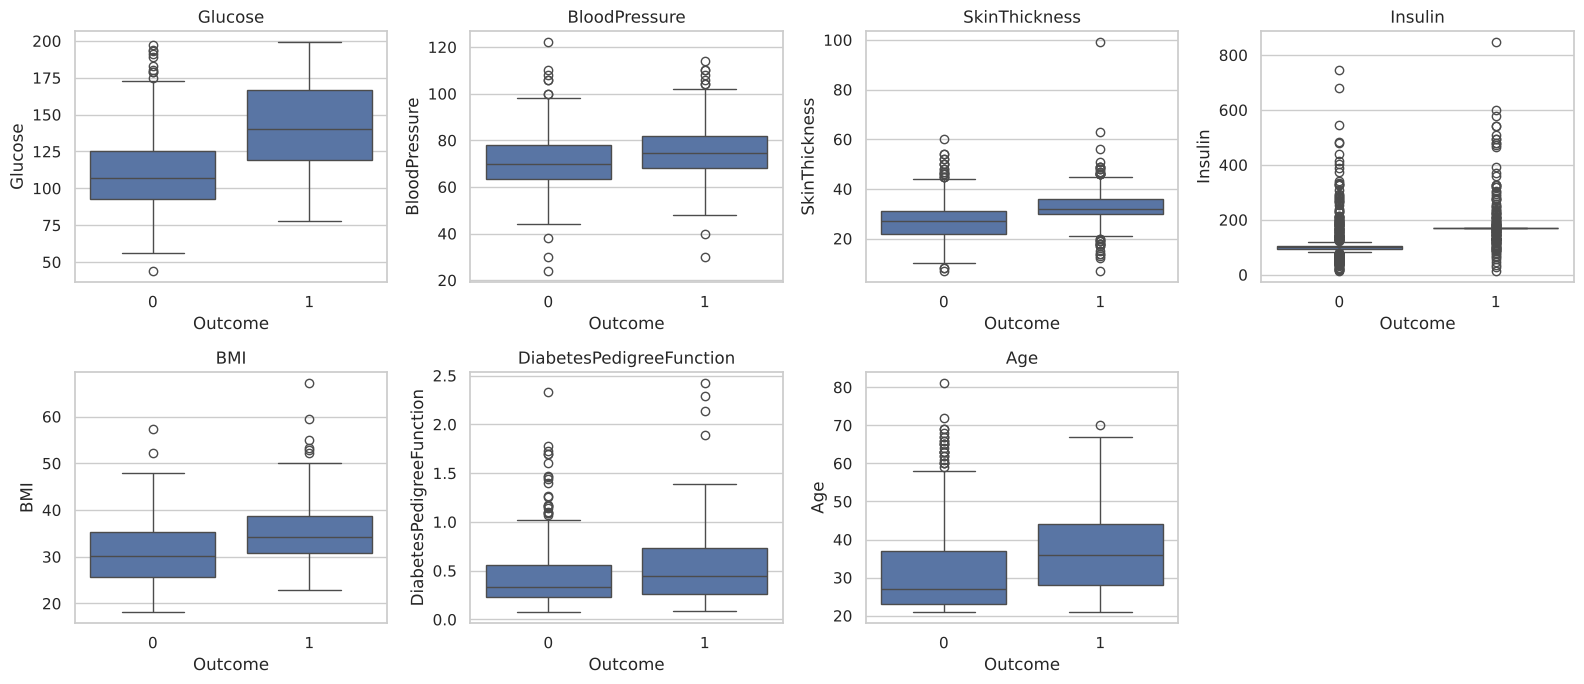

In [4]:
feats = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), feats):
    sns.boxplot(data=df, x="Outcome", y=c, ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

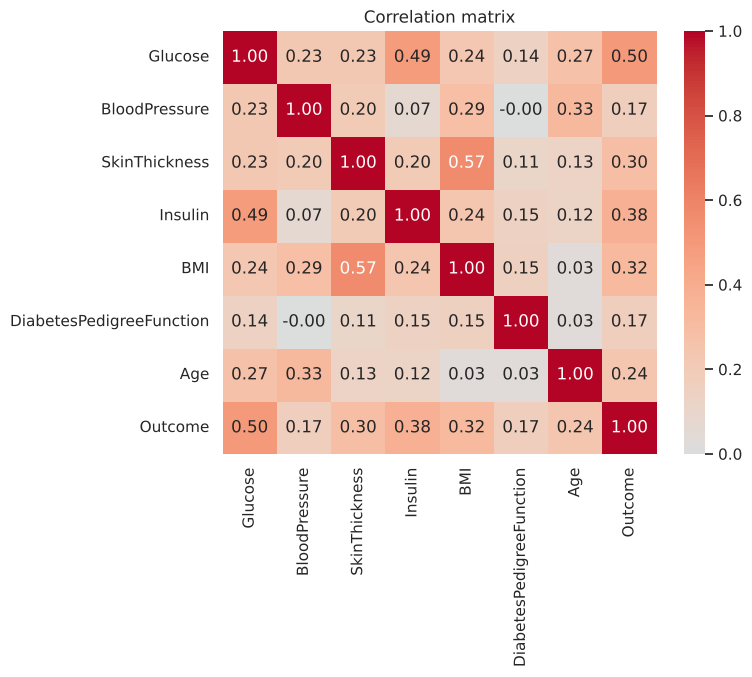

Correlation of each feature with Outcome:
Glucose                     0.496
Insulin                     0.377
BMI                         0.316
SkinThickness               0.295
Age                         0.238
BloodPressure               0.174
DiabetesPedigreeFunction    0.174


In [5]:
corr = df.corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()
print("Correlation of each feature with Outcome:")
print(corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3).to_string())

## 2. Split and scale
The split is stratified so train and test keep the same share of diabetic patients. The scaler is fitted on the training part only and then applied to the test part, so no information from the test set leaks into preprocessing. Scaling also makes the coefficients comparable across features.

In [6]:
X = df[feats]; y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("train:", X_train.shape, " test:", X_test.shape)
print("diabetic share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train); Xte = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=RS).fit(Xtr, y_train)
print(model)

train: (614, 7)  test: (154, 7)
diabetic share  train: 0.349  test: 0.351
LogisticRegression(max_iter=1000, random_state=42)


## 3. Evaluate

In [7]:
pred = model.predict(Xte)
proba = model.predict_proba(Xte)[:, 1]
acc = accuracy_score(y_test, pred)
print(f"Accuracy : {acc:.4f}   (baseline {y_test.value_counts(normalize=True).max():.4f})")
print(f"Precision: {precision_score(y_test, pred):.4f}")
print(f"Recall   : {recall_score(y_test, pred):.4f}")
print(f"F1       : {f1_score(y_test, pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, proba):.4f}")
print(f"Train accuracy: {accuracy_score(y_train, model.predict(Xtr)):.4f}")
print()
print(classification_report(y_test, pred, target_names=["No diabetes", "Diabetes"]))

Accuracy : 0.7273   (baseline 0.6494)
Precision: 0.6250
Recall   : 0.5556
F1       : 0.5882
ROC AUC  : 0.8174
Train accuracy: 0.7964

              precision    recall  f1-score   support

 No diabetes       0.77      0.82      0.80       100
    Diabetes       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154



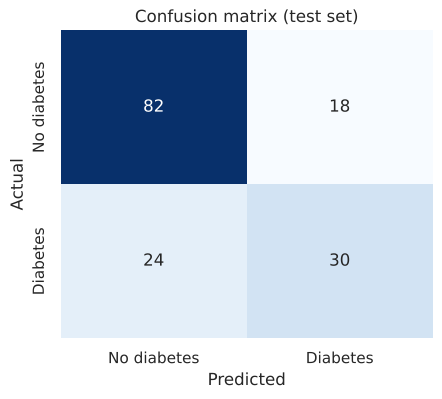

True negatives 82, false positives 18, false negatives 24, true positives 30
Of 54 diabetic patients in the test set, the model found 30 and missed 24.
Of 48 patients it flagged as diabetic, 30 really were.


In [8]:
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No diabetes", "Diabetes"], yticklabels=["No diabetes", "Diabetes"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)"); plt.show()
print(f"True negatives {tn}, false positives {fp}, false negatives {fn}, true positives {tp}")
print(f"Of {fn+tp} diabetic patients in the test set, the model found {tp} and missed {fn}.")
print(f"Of {tp+fp} patients it flagged as diabetic, {tp} really were.")

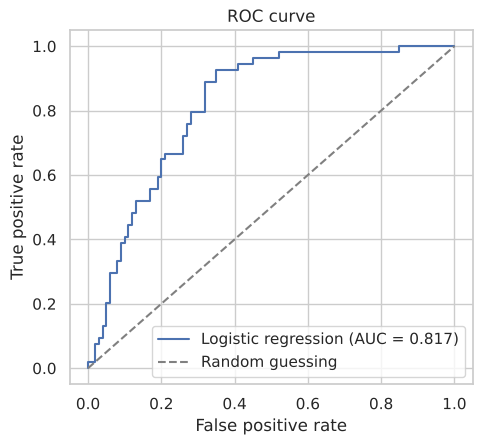

In [9]:
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5.2, 4.6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve")
plt.legend(); plt.show()

## 4. Coefficients and odds ratios
Because the features are standardised, each coefficient is the change in the log-odds of diabetes for a one-standard-deviation increase in that feature. Taking `exp(coefficient)` gives the odds ratio: values above 1 raise the odds, values below 1 lower them.

Intercept: -0.877


,feature,coefficient,odds_ratio_per_1SD,1SD_in_original_units
0,Glucose,0.918,2.504,30.007
1,Insulin,0.631,1.879,81.628
2,BMI,0.442,1.556,6.824
3,Age,0.310,1.364,11.824
4,SkinThickness,0.301,1.351,8.979
5,DiabetesPedigreeFunction,0.153,1.166,0.330
6,BloodPressure,0.019,1.019,12.273


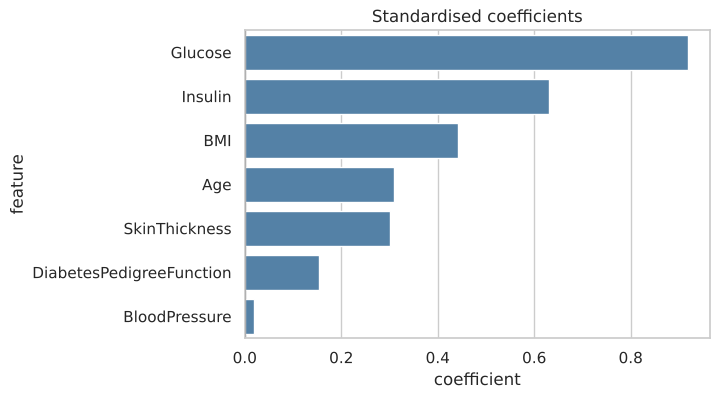

Largest positive effect: Glucose (odds x2.504 per 1 SD, i.e. 30.01 original units)
Smallest effect (most negative or closest to 0 at the bottom): BloodPressure (odds x1.019)


In [10]:
coef = pd.DataFrame({"feature": feats, "coefficient": model.coef_[0]})
coef["odds_ratio_per_1SD"] = np.exp(coef["coefficient"])
coef["1SD_in_original_units"] = scaler.scale_
coef = coef.sort_values("coefficient", ascending=False).round(3)
print("Intercept:", round(float(model.intercept_[0]), 3))
display(coef.reset_index(drop=True))

plt.figure(figsize=(6, 4))
sns.barplot(data=coef, y="feature", x="coefficient", color="steelblue")
plt.axvline(0, color="black", lw=0.8); plt.title("Standardised coefficients"); plt.show()

top = coef.iloc[0]; bot = coef.iloc[-1]
print(f"Largest positive effect: {top.feature} (odds x{top.odds_ratio_per_1SD} per 1 SD, i.e. {top['1SD_in_original_units']:.2f} original units)")
print(f"Smallest effect (most negative or closest to 0 at the bottom): {bot.feature} (odds x{bot.odds_ratio_per_1SD})")

## 5. Threshold: precision against recall
The default threshold is 0.5. In a screening setting a missed patient (false negative) is usually worse than a false alarm, so lowering the threshold trades precision for recall.

In [11]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)})
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,f1
0,0.3,0.727,0.581,0.796,0.672
1,0.4,0.734,0.610,0.667,0.637
2,0.5,0.727,0.625,0.556,0.588
3,0.6,0.740,0.675,0.500,0.574


## 6. Cross-validation
A single split can be lucky or unlucky, so the score is also checked with 5-fold stratified cross-validation. Shuffling is switched on and the scaler sits inside a pipeline, so it is refitted on each training fold.

In [12]:
pipe = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, random_state=RS))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
for metric in ["accuracy", "recall", "roc_auc"]:
    s = cross_val_score(pipe, X, y, cv=cv, scoring=metric)
    print(f"{metric:9s} folds={np.round(s, 3)}  mean={s.mean():.3f}  std={s.std():.3f}")

accuracy  folds=[0.747 0.838 0.766 0.784 0.719]  mean=0.771  std=0.040
recall    folds=[0.574 0.611 0.556 0.566 0.604]  mean=0.582  std=0.022


roc_auc   folds=[0.838 0.887 0.884 0.839 0.819]  mean=0.853  std=0.027


## 7. Save the model and predict for a new patient

In [13]:
final = pipe.fit(X_train, y_train)
joblib.dump(final, "diabetes_model.joblib")

# One new patient (the values used in the reference notebook)
new = pd.DataFrame([{"Age": 21, "BMI": 35.7, "BloodPressure": 75.0, "Insulin": 102.5, "Glucose": 112, "DiabetesPedigreeFunction": 0.148,
                     "SkinThickness": X["SkinThickness"].median()}])[feats]
loaded = joblib.load("diabetes_model.joblib")
p = loaded.predict_proba(new)[0, 1]
print(f"Predicted probability of diabetes: {p:.3f} -> {'Diabetes' if p >= 0.5 else 'No diabetes'}")
print("SkinThickness was not in the reference example, so the training median was used.")

Predicted probability of diabetes: 0.148 -> No diabetes
SkinThickness was not in the reference example, so the training median was used.


## 8. Findings
- On the 154 test patients the model reaches 72.7% accuracy, against a 64.9% baseline for always answering "no diabetes". It does beat the baseline, but not by a wide margin.
- Recall is the weak point: it found 30 of the 54 diabetic patients (55.6%) and missed 24. Precision is 62.5%.
- ROC AUC is 0.817 on the test set (0.853 in cross-validation), so the model ranks patients far better than chance even though the 0.5 cut-off gives mediocre recall.
- The 5-fold cross-validated accuracy is 0.771 (std 0.040), higher than the single test split (0.727). The test split looks somewhat unlucky, and the true accuracy is probably nearer 0.77.
- Glucose is the strongest predictor (odds x2.5 per standard deviation, about 30 units of glucose). All coefficients are positive, so every feature pushes the prediction towards diabetes.
- Caveat: about 31% of Insulin values are the same filled-in value (102.5), so this column carries less real information than its correlation suggests.
